ЗАДАНИЕ 3: МОДЕЛИРОВАНИЕ ШУМА

Однокубитный шум p1 = 0.001
Двухкубитный шум p2 ∈ [0, 0.001, 0.005, 0.01, 0.02]

Исходная схема: 8 кубитов, глубина 5
Транспиленная: 8 кубитов, глубина 5
CCX в транспилированной: 2
CX в транспилированной: 3
Всего двухкубитных вентилей: 3

--- Результаты для разных p2 ---
p2       Доля правильных    Правильных/Всего
---------------------------------------------


/tmp/ipykernel_2936/2845746222.py:38: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  print(f"CCX в транспилированной: {sum(1 for op in qc_transpiled.data if op[0].name=='ccx')}")
/tmp/ipykernel_2936/2845746222.py:39: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  print(f"CX в транспилированной: {sum(1 for op in qc_transpiled.data if op[0].name=='cx')}")
/tmp/ipykernel_2936/2845746222.py:42: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  num_cx_transpiled = sum(1 for op in qc_transpi

0        1.0000             32/32
0.001    1.0000             32/32
0.005    1.0000             32/32
0.01     1.0000             32/32
0.02     1.0000             32/32


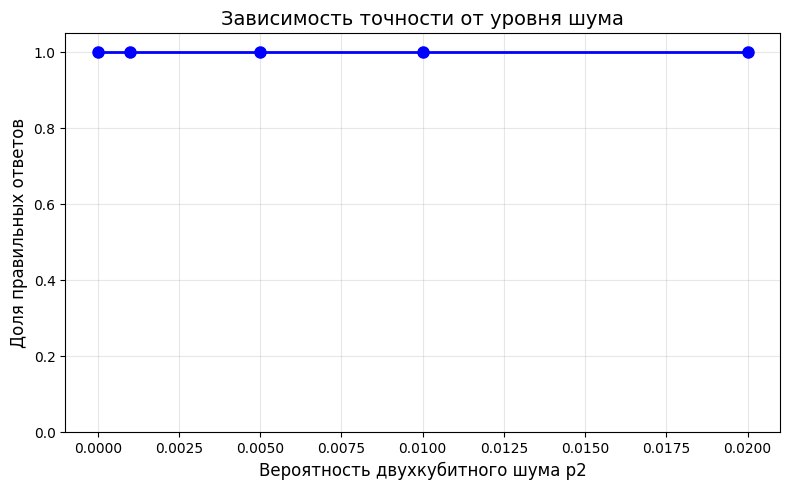


График сохранён: noise_analysis.png


In [4]:
# Задание 3: Моделирование работы схемы с шумом
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
import numpy as np

print("ЗАДАНИЕ 3: МОДЕЛИРОВАНИЕ ШУМА")

# Оптимизированная схема из задания 2
def build_F_for_noise():
    """F = (A&E) ⊕ (B&C) ⊕ D, 8 кубитов"""
    qc = QuantumCircuit(8, 1)
    qc.ccx(0, 4, 6)
    qc.ccx(1, 2, 7)
    qc.cx(6, 5)
    qc.cx(7, 5)
    qc.cx(3, 5)
    qc.measure(5, 0)
    return qc

def classical_F(a, b, c, d, e):
    return ((a & e) ^ (b & c) ^ d) & 1

# Параметры шума
p1 = 0.001  # однокубитный деполяризующий шум
p2_values = [0, 0.001, 0.005, 0.01, 0.02]  # двухкубитный шум

print(f"\nОднокубитный шум p1 = {p1}")
print(f"Двухкубитный шум p2 ∈ {p2_values}")

# Транспиляция схемы в базис симулятора
qc_base = build_F_for_noise()
simulator = AerSimulator()
qc_transpiled = transpile(qc_base, simulator)

print(f"\nИсходная схема: {qc_base.num_qubits} кубитов, глубина {qc_base.depth()}")
print(f"Транспиленная: {qc_transpiled.num_qubits} кубитов, глубина {qc_transpiled.depth()}")
print(f"CCX в транспилированной: {sum(1 for op in qc_transpiled.data if op[0].name=='ccx')}")
print(f"CX в транспилированной: {sum(1 for op in qc_transpiled.data if op[0].name=='cx')}")

# Подсчёт двухкубитных вентилей в транслированной схеме
num_cx_transpiled = sum(1 for op in qc_transpiled.data if op[0].name in ['cx', 'cz', 'swap'])
print(f"Всего двухкубитных вентилей: {num_cx_transpiled}")


# Запуск с разными уровнями шума

print("\n--- Результаты для разных p2 ---")
print(f"{'p2':<8} {'Доля правильных':<18} {'Правильных/Всего'}")
print("-"*45)

accuracy_results = {}

for p2 in p2_values:
    noise_model = NoiseModel()

    # Однокубитный деполяризующий шум
    error_1q = depolarizing_error(p1, 1)
    noise_model.add_all_qubit_quantum_error(error_1q, ['u1', 'u2', 'u3', 'h', 'x', 'z'])

    # Двухкубитный деполяризующий шум
    if p2 > 0:
        error_2q = depolarizing_error(p2, 2)
        noise_model.add_all_qubit_quantum_error(error_2q, ['cx', 'cz', 'swap'])

    sim = AerSimulator(noise_model=noise_model)

    correct_count = 0
    total_tests = 32  # 2^5 входов
    shots_per_test = 1000

    for idx in range(total_tests):
        a = (idx >> 4) & 1
        b = (idx >> 3) & 1
        c = (idx >> 2) & 1
        d = (idx >> 1) & 1
        e = idx & 1

        expected = classical_F(a, b, c, d, e)

        qc_test = QuantumCircuit(8, 1)
        if a: qc_test.x(0)
        if b: qc_test.x(1)
        if c: qc_test.x(2)
        if d: qc_test.x(3)
        if e: qc_test.x(4)

        qc_test.ccx(0, 4, 6)
        qc_test.ccx(1, 2, 7)
        qc_test.cx(6, 5)
        qc_test.cx(7, 5)
        qc_test.cx(3, 5)
        qc_test.measure(5, 0)

        qc_t = transpile(qc_test, sim)
        job = sim.run(qc_t, shots=shots_per_test)
        counts = job.result().get_counts()

        # Majority vote
        if counts:
            most_common = max(counts.items(), key=lambda x: x[1])
            result_bit = int(most_common[0][0])
            if result_bit == expected:
                correct_count += 1

    accuracy = correct_count / total_tests
    accuracy_results[p2] = accuracy
    print(f"{p2:<8} {accuracy:<18.4f} {correct_count}/{total_tests}")


# График зависимости точности от p2

try:
    import matplotlib.pyplot as plt

    p2_arr = list(accuracy_results.keys())
    acc_arr = list(accuracy_results.values())

    plt.figure(figsize=(8, 5))
    plt.plot(p2_arr, acc_arr, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('Вероятность двухкубитного шума p2', fontsize=12)
    plt.ylabel('Доля правильных ответов', fontsize=12)
    plt.title('Зависимость точности от уровня шума', fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.ylim([0, 1.05])
    plt.tight_layout()
    plt.savefig('noise_analysis.png', dpi=150)
    plt.show()
    print("\nГрафик сохранён: noise_analysis.png")
except ImportError:
    print("\nmatplotlib недоступен, пропуск графика")